# Pertemuan 7 — Pembangunan Model ARIMA/SARIMA
## Notebook Praktikum · Analisis Runtun Waktu (SDT-3329)

**Program Studi Sains Data · Fakultas Digital, Desain dan Bisnis · Institut Teknologi Sains Bandung**
Semester 6 · 3 SKS (T: 2, P: 1) · Mata kuliah syarat: Statistika Komputasi, Pemrograman Statistika, Aljabar Linear ·
Dosen pengampu: Bakti Siregar, S.Si., M.Sc

---

### Keselarasan dengan RPS (OBE)

| Komponen | Isi |
|---|---|
| **Kemampuan akhir (Sub-CPMK)** | Mahasiswa mampu membangun dan melatih model ARIMA/SARIMA pada data runtun waktu. |
| **CPL / CPMK** | CPL-1 · CPL-2 · CPMK-3 |
| **Indikator** | Mampu mengimplementasikan model ARIMA/SARIMA menggunakan perangkat lunak dan melakukan peramalan. |
| **Kriteria penilaian** | Ketepatan pembangunan model dan kemampuan peramalan. |
| **Materi pembelajaran** | Estimasi parameter, fitting model, diagnostik residual awal, peramalan dengan ARIMA/SARIMA. |
| **Konsep pemrograman** | Estimasi AR dengan aljabar matriks dari nol; OOP: kelas pembungkus `PeramalSARIMA` dengan antarmuka seragam (bagian 🧠) |
| **Bobot penilaian minggu ini** | 4% |
| **Alokasi waktu** | TM 2 × 50′ · Praktikum 1 × 170′ · PT 2 × 60′ · BM 2 × 60′ |
| **Keterkaitan tugas (RTM)** | Tugas 2 (P7–P9): Pemodelan dan Evaluasi dengan Metode Klasik — dimulai |
| **Pustaka** | Hyndman & Athanasopoulos (2021) Bab 9.7–9.10; Box dkk. (2015) Bab 7–8 |

**Dataset:** Pertumbuhan PDB riil AS · Airline Passengers · Penjualan mobil bulanan Quebec
**Pustaka Python:** pandas · NumPy · Matplotlib · seaborn · statsmodels

### Peta notebook

| Bagian | Isi | Indikator RPS |
|---|---|---|
| 1 | Estimasi parameter: OLS dari nol, Yule–Walker, *maximum likelihood* | Estimasi parameter |
| 2 | Fitting SARIMA "airline" dan membaca ringkasan model | **Fitting model** |
| 3 | Diagnostik residual awal | Diagnostik residual awal |
| 4 | Peramalan: mekanika ramalan ARIMA, interval, transformasi balik dari log | **Kemampuan peramalan** |
| 5 | Studi kasus kedua: penjualan mobil — SARIMA vs Holt-Winters (P5) | Kemampuan peramalan |
| 6 | 🧠 Konsep pemrograman: kelas pembungkus `PeramalSARIMA` dengan antarmuka seragam | — |
| 7 | Latihan (Tugas 2), ringkasan, logbook | — |

### Cara menggunakan notebook ini

- Jalankan sel berurutan (Google Colab atau Jupyter lokal). Di Colab, `statsmodels` sudah tersedia; `arch` (P11) dipasang dengan `pip install arch`.
- Sel **LATIHAN** berisi `TODO`; lengkapi selama praktikum. Bagian 🧠 **Konsep Pemrograman** menjelaskan prinsip di balik kode,
  bukan sekadar cara memanggil pustaka.
- Penilaian memakai rubrik RPS — *Kualitas Implementasi (Kode & Model)* dan *Interpretasi & Visualisasi Hasil* — serta
  Rubrik PRAKTIKUM (eksekusi 40%, pembersihan data 35%, penanganan error & modularitas 25%).
- Unggah notebook dan logbook ke LMS/Virtual Lab setelah praktikum.

---
## 0. Persiapan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'figure.figsize': (10, 3.4)})
pd.set_option('display.width', 140)
RANDOM_STATE = 42
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.regression.linear_model import yule_walker
from statsmodels.stats.diagnostic import acorr_ljungbox

air = pd.read_csv('https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv', parse_dates=['Month'], index_col='Month')['Passengers'].asfreq('MS')
car = pd.read_csv('https://raw.githubusercontent.com/jbrownlee/Datasets/master/monthly-car-sales.csv', parse_dates=['Month'], index_col='Month')['Sales'].asfreq('MS')
mac = sm.datasets.macrodata.load_pandas().data
mac.index = pd.period_range('1959Q1', periods=len(mac), freq='Q').to_timestamp(); mac = mac.asfreq('QS')
gdp_g = (np.log(mac.realgdp).diff() * 100).dropna().rename('pertumbuhan')

def mape(a, f): return float(100 * np.mean(np.abs((np.asarray(a) - np.asarray(f)) / np.asarray(a))))
def rmse(a, f): return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(f)) ** 2)))

---
## 1. Estimasi Parameter

Tiga pendekatan untuk AR(p):

| Metode | Ide | Catatan |
|---|---|---|
| **OLS bersyarat** | Regresikan $y_t$ pada $y_{t-1}, \dots, y_{t-p}$ | Sederhana; mengabaikan p pengamatan pertama |
| **Yule–Walker** | Samakan autokorelasi teori dengan sampel | Selalu menghasilkan model stasioner |
| **Maximum likelihood (MLE)** | Maksimalkan likelihood Gaussian lengkap (via Kalman filter, P13) | Standar statsmodels; berlaku untuk MA dan musiman |

Komponen MA tidak dapat diestimasi dengan OLS karena $\varepsilon_{t-1}$ tidak teramati — itulah alasan MLE dibutuhkan.

In [2]:
def ar_ols(y, p):
    """Estimasi AR(p) dengan OLS dari nol: menyusun matriks lag lalu (X'X)^-1 X'y."""
    y = np.asarray(y, float)
    X = np.column_stack([np.ones(len(y) - p)] + [y[p - k:len(y) - k] for k in range(1, p + 1)])
    target = y[p:]
    beta = np.linalg.solve(X.T @ X, X.T @ target)
    resid = target - X @ beta
    s2 = resid @ resid / (len(target) - X.shape[1])
    se = np.sqrt(np.diag(s2 * np.linalg.inv(X.T @ X)))
    return beta, se, np.sqrt(s2)

b, se, s = ar_ols(gdp_g, 2)
rho, sig = yule_walker(gdp_g.values, order=2, method='mle')
mle = ARIMA(gdp_g, order=(2, 0, 0), trend='c').fit()
c_mle = mle.params['const'] * (1 - mle.params['ar.L1'] - mle.params['ar.L2'])     # statsmodels melaporkan RATA-RATA, bukan intersep
tab = pd.DataFrame({'OLS (sendiri)': [b[0], b[1], b[2], s], 'Yule–Walker': [np.nan, rho[0], rho[1], sig],
                    'MLE (statsmodels)': [c_mle, mle.params['ar.L1'], mle.params['ar.L2'], np.sqrt(mle.params['sigma2'])]},
                   index=['intersep c', 'φ₁', 'φ₂', 'σ'])
print(tab.round(4)); print(f'\nSE OLS φ₁, φ₂: {se[1]:.3f}, {se[2]:.3f} | SE MLE: {mle.bse["ar.L1"]:.3f}, {mle.bse["ar.L2"]:.3f}')
print(f"Rata-rata proses = c / (1 − φ₁ − φ₂) = {b[0] / (1 - b[1] - b[2]):.3f}% per kuartal (MLE melaporkan 'const' = {mle.params['const']:.3f})")

            OLS (sendiri)  Yule–Walker  MLE (statsmodels)
intersep c         0.4410          NaN             0.4539
φ₁                 0.2687       0.2525             0.2540
φ₂                 0.1594       0.1631             0.1632
σ                  0.8212       0.8255             0.8249

SE OLS φ₁, φ₂: 0.070, 0.069 | SE MLE: 0.063, 0.062
Rata-rata proses = c / (1 − φ₁ − φ₂) = 0.771% per kuartal (MLE melaporkan 'const' = 0.779)


> Ketiga metode memberi estimasi yang sangat dekat pada sampel berukuran 200. Satu jebakan umum: kolom `const` statsmodels
> pada ARIMA adalah **rata-rata proses** $\mu$, bukan intersep $c$ pada persamaan regresi; hubungannya $c = \mu(1-\phi_1-\phi_2)$.

---
## 2. Fitting SARIMA Model Airline

Dari P6: SARIMA$(0,1,1)(0,1,1)_{12}$ pada $\log y$. Sisihkan 24 bulan terakhir sebagai data uji.

In [3]:
ly = np.log(air)
latih, uji = ly[:-24], ly[-24:]
airline = SARIMAX(latih, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
print(airline.summary().tables[1])
print(f'AICc = {airline.aicc:.2f} | BIC = {airline.bic:.2f} | log-likelihood = {airline.llf:.2f}')

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.3429      0.087     -3.928      0.000      -0.514      -0.172
ma.S.L12      -0.5410      0.105     -5.161      0.000      -0.746      -0.336
sigma2         0.0014      0.000      7.866      0.000       0.001       0.002
AICc = -388.78 | BIC = -380.99 | log-likelihood = 197.50


**Membaca tabel koefisien**

| Kolom | Arti |
|---|---|
| `coef` | Estimasi parameter: `ma.L1` = θ₁, `ma.S.L12` = Θ₁, `sigma2` = varians galat |
| `std err`, `z`, `P>|z|` | Uji apakah parameter berbeda dari nol |
| `[0.025 0.975]` | Interval kepercayaan 95% |

> θ₁ ≈ −0,34 dan Θ₁ ≈ −0,54: keduanya signifikan. Persamaan model:
> $(1-B)(1-B^{12})\log y_t = (1 + \theta_1 B)(1 + \Theta_1 B^{12})\varepsilon_t$. Nilai negatif berarti sebagian guncangan
> bulan lalu dan tahun lalu "dikoreksi" — ramalan merupakan rata-rata berbobot antara pola musiman tahun lalu dan level terbaru.
> Box & Jenkins (1970) melaporkan nilai yang mirip untuk seluruh data (θ ≈ −0,40, Θ ≈ −0,61).

---
## 3. Diagnostik Residual Awal

Model yang baik meninggalkan residu menyerupai **white noise**: tanpa autokorelasi, rata-rata nol, varians konstan,
idealnya mendekati normal. Diagnostik lengkap dibahas di P10.

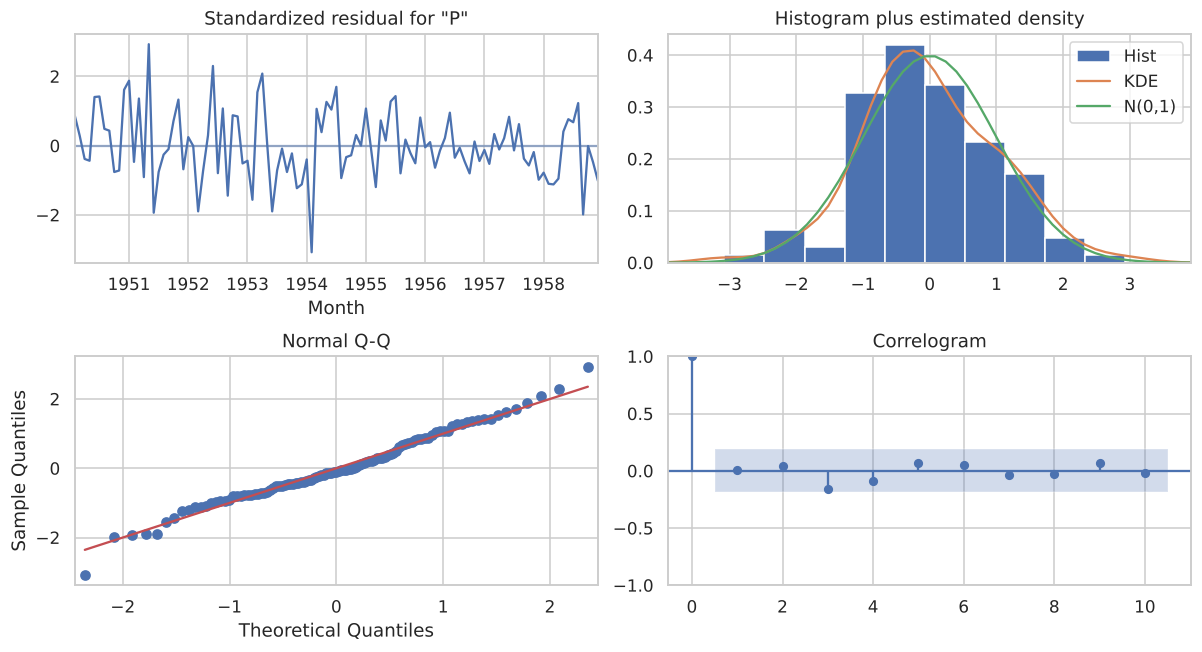

Ljung-Box p-value: {6: 0.559, 12: 0.912, 24: 0.804}
Rata-rata residu 0.0003 | std 0.0386 (≈ 3.9% galat relatif karena skala log)


In [4]:
fig = airline.plot_diagnostics(figsize=(11, 6)); plt.tight_layout(); plt.show()
res = airline.resid.iloc[13:]                     # 13 residu awal tidak informatif akibat differencing
lb = acorr_ljungbox(res, lags=[6, 12, 24])
print('Ljung-Box p-value:', lb.lb_pvalue.round(3).to_dict())
print(f'Rata-rata residu {res.mean():.4f} | std {res.std():.4f} (≈ {res.std()*100:.1f}% galat relatif karena skala log)')

> Semua p-value Ljung-Box > 0,05 → tidak ada bukti autokorelasi tersisa; histogram dan Q-Q plot mendekati normal; korelogram
> berada di dalam pita. Model layak dipakai untuk peramalan.

---
## 4. Peramalan

### 4.1 Mekanika ramalan ARIMA
Ramalan = **ekspektasi bersyarat** $\hat y_{T+h|T} = E[y_{T+h} \mid y_1, \dots, y_T]$: ganti galat masa depan dengan 0 dan nilai
masa depan dengan ramalannya. Untuk AR(1) dengan rata-rata μ: $\hat y_{T+h} = \mu + \phi^h (y_T - \mu)$ → kembali ke rata-rata.

Ramalan manual  : [0.751 0.771 0.777 0.779 0.779]
Ramalan statsmodels: [0.751 0.771 0.777 0.779 0.779]


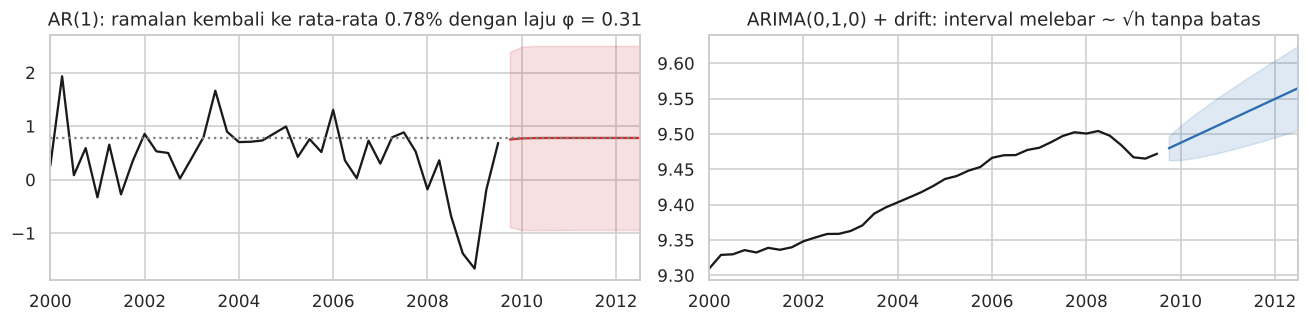

In [5]:
ar1 = ARIMA(gdp_g, order=(1, 0, 0)).fit()
mu, phi = ar1.params['const'], ar1.params['ar.L1']
h = np.arange(1, 13)
manual = mu + phi ** h * (gdp_g.iloc[-1] - mu)
sm_f = ar1.get_forecast(12)
print('Ramalan manual  :', manual[:5].round(3))
print('Ramalan statsmodels:', sm_f.predicted_mean.values[:5].round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
gdp_g['2000':].plot(ax=ax[0], color='k'); sm_f.predicted_mean.plot(ax=ax[0], color='#c53030')
ci = sm_f.conf_int(); ax[0].fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color='#c53030', alpha=.15)
ax[0].axhline(mu, ls=':', color='grey'); ax[0].set_title(f'AR(1): ramalan kembali ke rata-rata {mu:.2f}% dengan laju φ = {phi:.2f}')
rw = ARIMA(np.log(mac.realgdp), order=(0, 1, 0), trend='t').fit().get_forecast(12)
np.log(mac.realgdp)['2000':].plot(ax=ax[1], color='k'); rw.predicted_mean.plot(ax=ax[1], color='#2b6cb0')
ci2 = rw.conf_int(); ax[1].fill_between(ci2.index, ci2.iloc[:, 0], ci2.iloc[:, 1], color='#2b6cb0', alpha=.15)
ax[1].set_title('ARIMA(0,1,0) + drift: interval melebar ~ √h tanpa batas')
plt.tight_layout(); plt.show()

> Model **stasioner** (AR) memiliki ramalan yang kembali ke rata-rata dan interval yang **berhenti melebar**; model dengan
> **differencing** (akar unit) memiliki interval yang terus melebar — ketidakpastian jangka panjang tak terbatas.

### 4.2 Ramalan Airline dan transformasi balik dari log

Bila model dibangun pada $\log y$, maka $\exp(\hat{\log y})$ adalah **median** ramalan. Rata-rata memerlukan koreksi bias
$\exp(\hat{\log y} + \tfrac12\sigma_h^2)$. Interval prediksi cukup ditransformasi balik ujung-ujungnya.

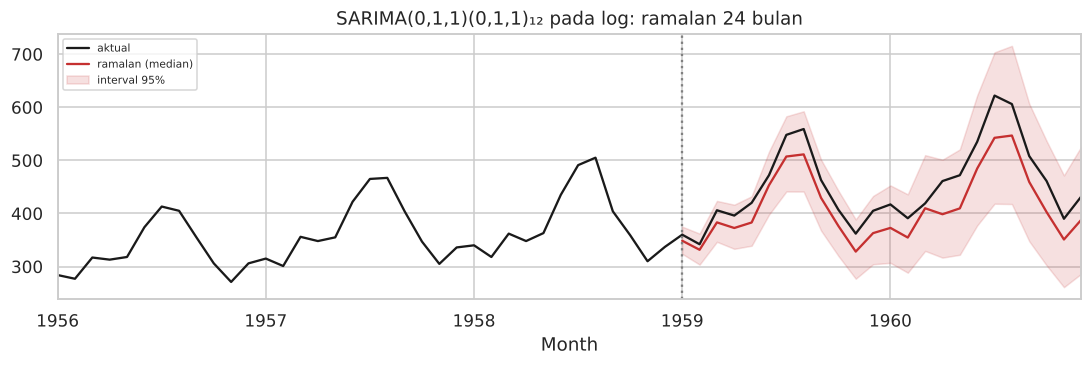

MAPE median 8.51% | MAPE rata-rata terkoreksi 8.02% | cakupan interval 95%: 100%
Pembanding — seasonal naive: 15.52% | Holt-Winters multiplikatif: 6.39%


In [6]:
fc = airline.get_forecast(24)
sf = fc.summary_frame(alpha=0.05)
median = np.exp(sf['mean']); rata = np.exp(sf['mean'] + sf['mean_se'] ** 2 / 2)
bawah, atas = np.exp(sf['mean_ci_lower']), np.exp(sf['mean_ci_upper'])
aktual = air[-24:]
fig, ax = plt.subplots(figsize=(10, 3.4))
air['1956':].plot(ax=ax, color='k', label='aktual'); median.plot(ax=ax, color='#c53030', label='ramalan (median)')
ax.fill_between(sf.index, bawah, atas, color='#c53030', alpha=.15, label='interval 95%'); ax.axvline(uji.index[0], color='grey', ls=':')
ax.legend(fontsize=7); ax.set_title('SARIMA(0,1,1)(0,1,1)₁₂ pada log: ramalan 24 bulan'); plt.tight_layout(); plt.show()
cakup = ((aktual >= bawah) & (aktual <= atas)).mean()
print(f'MAPE median {mape(aktual, median):.2f}% | MAPE rata-rata terkoreksi {mape(aktual, rata):.2f}% | cakupan interval 95%: {cakup:.0%}')

snaive = np.tile(air[-36:-24].values, 2)
hw = ExponentialSmoothing(air[:-24], trend='add', seasonal='mul', seasonal_periods=12, initialization_method='estimated').fit().forecast(24)
print(f'Pembanding — seasonal naive: {mape(aktual, snaive):.2f}% | Holt-Winters multiplikatif: {mape(aktual, hw):.2f}%')

> SARIMA pada log (MAPE ±8%) jauh mengalahkan seasonal naive (±15,5%) dan interval 95%-nya mencakup seluruh 24 nilai aktual.
> Namun pada periode uji ini Holt-Winters multiplikatif **lebih akurat** (±6,4%). Model yang residunya "sempurna" belum tentu
> peramal terbaik — kedua hal itu dievaluasi terpisah (P9 dan P10). Koreksi bias memperbaiki MAPE sedikit (8,5% → 8,0%) karena
> σ (galat ±4%) kecil.

---
## 5. Studi Kasus Kedua: Penjualan Mobil Quebec

In [7]:
import itertools
latih_c, uji_c = car[:-12], car[-12:]
kandidat = []
for p, q, P, Q in itertools.product([0, 1], [0, 1], [0, 1], [0, 1]):
    try:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')                 # beberapa kandidat tidak konvergen; diabaikan di pencarian kecil ini
            m = SARIMAX(np.log(latih_c), order=(p, 1, q), seasonal_order=(P, 1, Q, 12)).fit(disp=False)
        kandidat.append(((p, 1, q, P, 1, Q), m.aicc, m))
    except Exception:
        continue
kandidat.sort(key=lambda x: x[1])
orde, aicc, best = kandidat[0]
f_sar = np.exp(best.get_forecast(12).predicted_mean)
f_hw = ExponentialSmoothing(latih_c, trend='add', seasonal='add', seasonal_periods=12, initialization_method='estimated').fit().forecast(12)
f_sn = latih_c.iloc[-12:].values
print(f'SARIMA terbaik (AICc, pada log): ({orde[0]},1,{orde[2]})({orde[3]},1,{orde[5]})₁₂ AICc={aicc:.2f}')
print(f'MAPE uji 12 bulan — SARIMA: {mape(uji_c, f_sar):.2f}% | HW aditif (P5): {mape(uji_c, f_hw):.2f}% | seasonal naive: {mape(uji_c, f_sn):.2f}%')
print('Ljung-Box p (lag 12) residu SARIMA:', round(acorr_ljungbox(best.resid.iloc[13:], lags=[12]).lb_pvalue.iloc[0], 3))

SARIMA terbaik (AICc, pada log): (0,1,1)(0,1,1)₁₂ AICc=-108.00
MAPE uji 12 bulan — SARIMA: 8.57% | HW aditif (P5): 7.21% | seasonal naive: 10.83%
Ljung-Box p (lag 12) residu SARIMA: 0.149


> Pada penjualan mobil, model airline kembali terpilih; Holt-Winters aditif sedikit lebih akurat (7,2% vs 8,6%) dan keduanya
> mengalahkan seasonal naive (10,8%).
> Tidak ada satu keluarga model yang selalu menang — inilah alasan Tugas 2 meminta perbandingan **minimal dua metode**
> pemulusan dan model ARIMA/SARIMA dengan metrik yang sama.

---
## 6. 🧠 Konsep Pemrograman — Kelas Pembungkus dengan Antarmuka Seragam

Kode di Bagian 4 mengulang langkah yang sama: transformasi log → fit → ramal → transformasi balik → interval. Pengulangan
seperti ini rawan galat (lupa `exp`, lupa koreksi bias). **Enkapsulasi** dalam kelas:

| Prinsip | Penerapan |
|---|---|
| Antarmuka seragam | `fit(y)` → `forecast(h)` mengembalikan DataFrame `ramalan, bawah, atas` — sama untuk semua model (P14) |
| Enkapsulasi | Transformasi log dan transformasi balik tersembunyi di dalam kelas |
| Validasi | Galat jelas bila data mengandung nilai ≤ 0 saat `log=True`, atau bila `forecast` dipanggil sebelum `fit` |
| *Fail fast* | Memeriksa frekuensi indeks agar tanggal ramalan benar |

In [8]:
class PeramalSARIMA:
    """Pembungkus SARIMAX dengan opsi transformasi log dan transformasi balik otomatis."""

    def __init__(self, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12), log=True, alpha=0.05):
        self.order, self.seasonal_order, self.log, self.alpha = order, seasonal_order, log, alpha

    def fit(self, y):
        if not isinstance(y.index, pd.DatetimeIndex) or y.index.freq is None:
            raise ValueError('y harus ber-DatetimeIndex dengan frekuensi (gunakan .asfreq())')
        if self.log and (y <= 0).any():
            raise ValueError('log=True memerlukan semua nilai > 0')
        z = np.log(y) if self.log else y
        self.hasil_ = SARIMAX(z, order=self.order, seasonal_order=self.seasonal_order).fit(disp=False)
        return self

    def forecast(self, h):
        if not hasattr(self, 'hasil_'):
            raise RuntimeError('panggil fit() terlebih dahulu')
        sf = self.hasil_.get_forecast(h).summary_frame(alpha=self.alpha)
        if not self.log:
            return pd.DataFrame({'ramalan': sf['mean'], 'bawah': sf['mean_ci_lower'], 'atas': sf['mean_ci_upper']})
        return pd.DataFrame({'ramalan': np.exp(sf['mean'] + sf['mean_se'] ** 2 / 2),     # rata-rata terkoreksi bias
                             'bawah': np.exp(sf['mean_ci_lower']), 'atas': np.exp(sf['mean_ci_upper'])})

    def __repr__(self):
        return f'PeramalSARIMA{self.order}{self.seasonal_order[:3]}_{self.seasonal_order[3]} log={self.log} fit={hasattr(self, "hasil_")}'

model = PeramalSARIMA().fit(air[:-24])
print(model); print(model.forecast(3).round(1))
print(f'MAPE 24 bulan: {mape(air[-24:], model.forecast(24).ramalan):.2f}%')
for uji_kasus in [lambda: PeramalSARIMA().forecast(3), lambda: PeramalSARIMA().fit(air.reset_index(drop=True)),
                  lambda: PeramalSARIMA().fit(air - 200)]:
    try:
        uji_kasus()
    except (ValueError, RuntimeError) as e:
        print('Ditolak:', e)

PeramalSARIMA(0, 1, 1)(0, 1, 1)_12 log=True fit=True
            ramalan  bawah   atas
1959-01-01    348.8  323.9  375.1
1959-02-01    331.9  303.7  362.0
1959-03-01    383.7  346.6  423.6
MAPE 24 bulan: 8.02%
Ditolak: panggil fit() terlebih dahulu
Ditolak: y harus ber-DatetimeIndex dengan frekuensi (gunakan .asfreq())
Ditolak: log=True memerlukan semua nilai > 0


---
## 7. Latihan

### LATIHAN 1 — Tugas 2, langkah 3–4
Bangun model ARIMA/SARIMA hasil identifikasi P6 pada data Tugas Anda, tampilkan ringkasan koefisien dan diagnostik awal, lalu
buat ramalan dengan interval 95% untuk periode uji. Bandingkan dengan model pemulusan terbaik dari P5.

In [9]:
# TODO

### LATIHAN 2 — Kembangkan kelas
Tambahkan metode `plot(y_aktual=None)` dan `ringkasan()` (mengembalikan dict: orde, AICc, BIC, p-value Ljung-Box lag 12) ke
`PeramalSARIMA`.

In [10]:
# TODO

### LATIHAN 3 — Tanpa log
Bangun SARIMA(0,1,1)(0,1,1)₁₂ pada Airline **tanpa** log. Bandingkan MAPE, cakupan interval, dan plot residunya dengan versi log.

In [11]:
# TODO

---
## 8. Ringkasan Pertemuan 7

- ▸ AR dapat diestimasi dengan OLS/Yule–Walker; model dengan komponen MA memerlukan MLE.
- ▸ `const` pada ARIMA statsmodels = rata-rata proses μ, bukan intersep c.
- ▸ Baca ringkasan: koefisien, signifikansi, AICc/BIC; periksa residu (Ljung-Box, Q-Q plot) sebelum meramal.
- ▸ Ramalan = ekspektasi bersyarat; model stasioner kembali ke rata-rata, model terdifferensiasi memiliki interval yang terus melebar.
- ▸ Model pada log: transformasi balik memberi median; koreksi bias $\exp(\cdot + \sigma^2/2)$ untuk rata-rata.

### Tugas mandiri (PT & BM) — **Tugas 2 dimulai (P7–P9)**
**Tugas 2 (35%): Pemodelan dan Evaluasi dengan Metode Klasik** — minimal dua metode pemulusan, identifikasi & pembangunan
ARIMA/SARIMA, peramalan, metrik evaluasi (P9), diagnostik residual (P10). Persiapkan juga **UTS** (P1–P7).

**Pertemuan berikutnya:** `P08_UTS.ipynb`

---
## Logbook Praktikum — Pertemuan 7

Salin sel di bawah, isi, lalu unggah bersama notebook ke LMS/Virtual Lab (aktivitas PT & BM sesuai RPS).

In [12]:
logbook = {
    'Nama / NIM'                          : 'TODO',
    'Pertemuan'                           : 7,
    'Tanggal praktikum'                   : 'TODO',
    'Tiga temuan terpenting (dengan angka)': ['TODO', 'TODO', 'TODO'],
    'Galat yang ditemui & cara mengatasi' : 'TODO',
    'Latihan yang diselesaikan'           : 'TODO',
    'Pertanyaan untuk pertemuan berikutnya': 'TODO',
}
for k, v in logbook.items():
    print(f'{k:<38}: {v}')

Nama / NIM                            : TODO
Pertemuan                             : 7
Tanggal praktikum                     : TODO
Tiga temuan terpenting (dengan angka) : ['TODO', 'TODO', 'TODO']
Galat yang ditemui & cara mengatasi   : TODO
Latihan yang diselesaikan             : TODO
Pertanyaan untuk pertemuan berikutnya : TODO
